# Data Preprocessing Demo: Ecommerce Purchases (Week 3 lecture demo)

**What this notebook covers:** Part 1 explores a table of 10,000 made-up online purchases with pandas, answering one question per cell (the *Ecommerce Purchases* exercise, with its solutions). Part 2 prepares the same table for a machine-learning model with scikit-learn: it fills missing values, scales the numeric columns and one-hot encodes the text columns in one pipeline, then fits a linear regression, first to predict the purchase price and then a price band (0–20, 20–50 or 50–100).

**How to run it:** this notebook runs in your browser, so there is nothing to install. Click a code cell and press **Shift + Enter** to run it and move to the next one, or use **Run → Run All Cells**. Run the cells in order, because later cells use variables created earlier. The first code cell installs `seaborn` into the browser, which takes a few seconds the first time. The two cells that call `pipeline_model` take several minutes each in the browser.

**What to expect:** Part 1 gives single answers (for example, the average purchase price is about 50.35). In Part 2 the model fits the training rows almost perfectly (score close to 1.0) but scores below 0 on the test rows: it memorises the training data instead of learning a pattern. The real and predicted values it prints are a random sample, so they change every time you run it.

`Ecommerce Purchases.csv` is in the same folder as this notebook, so pandas finds it by name. All names, addresses and card numbers in it are fake.

## Part 1: Exploring the data with pandas

# ___
# Ecommerce Purchases Exercise - Solutions

In this Exercise you will be given some Fake Data about some purchases done through Amazon! Just go ahead and follow the directions and try your best to answer the questions and complete the tasks. Feel free to reference the solutions. Most of the tasks can be solved in different ways. For the most part, the questions get progressively harder.

Please excuse anything that doesn't make "Real-World" sense in the dataframe, all the data is fake and made-up.

Also note that all of these questions can be answered with one line of code.
____
**Import pandas and read in the Ecommerce Purchases csv file and set it to a DataFrame called ecom.**

In [26]:
%pip install seaborn
# Why: load the libraries used in this notebook. The %pip line above installs seaborn into the browser.
# Output: only pip messages; the first run takes a few seconds. Keep %pip as the first line of the cell.
# Note: style, GridSpec, sns and stats are imported but not used below; numpy (np), pandas (pd) and plt are.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import style
from matplotlib.gridspec import GridSpec
import seaborn as sns
from scipy import stats


In [2]:
# Why: read the CSV file into a DataFrame (a table) called `ecom`; every later cell uses it.
# Output: none. A FileNotFoundError means the CSV is not in the same folder as this notebook.
ecom = pd.read_csv('Ecommerce Purchases.csv')

**Check the head of the DataFrame.**

In [3]:
# Why: look at the first rows to see what each column contains.
# Output: a table with the first 5 rows and all 14 columns.
ecom.head()

,Address,Lot,AM or PM,Browser Info,Company,Credit Card,CC Exp Date,CC Security Code,CC Provider,Email,Job,IP Address,Language,Purchase Price
0,"16629 Pace Camp Apt. 448\nAlexisborough, NE 77...",46 in,PM,Opera/9.56.(X11; Linux x86_64; sl-SI) Presto/2...,Martinez-Herman,6011929061123406,02/20,900,JCB 16 digit,pdunlap@yahoo.com,"Scientist, product/process development",149.146.147.205,el,98.14
1,"9374 Jasmine Spurs Suite 508\nSouth John, TN 8...",28 rn,PM,Opera/8.93.(Windows 98; Win 9x 4.90; en-US) Pr...,"Fletcher, Richards and Whitaker",3337758169645356,11/18,561,Mastercard,anthony41@reed.com,Drilling engineer,15.160.41.51,fr,70.73
2,Unit 0065 Box 5052\nDPO AP 27450,94 vE,PM,Mozilla/5.0 (compatible; MSIE 9.0; Windows NT ...,"Simpson, Williams and Pham",675957666125,08/19,699,JCB 16 digit,amymiller@morales-harrison.com,Customer service manager,132.207.160.22,de,0.95
3,"7780 Julia Fords\nNew Stacy, WA 45798",36 vm,PM,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_8_0 ...,"Williams, Marshall and Buchanan",6011578504430710,02/24,384,Discover,brent16@olson-robinson.info,Drilling engineer,30.250.74.19,es,78.04
4,"23012 Munoz Drive Suite 337\nNew Cynthia, TX 5...",20 IE,AM,Opera/9.58.(X11; Linux x86_64; it-IT) Presto/2...,"Brown, Watson and Andrews",6011456623207998,10/25,678,Diners Club / Carte Blanche,christopherwright@gmail.com,Fine artist,24.140.33.94,es,77.82


**How many rows and columns are there?**

In [4]:
# Why: check the size of the table, the type of each column and whether values are missing.
# Output: 10000 entries (rows) and 14 columns, each with 10000 non-null values, so nothing is missing.
# Text columns show the type `str` (`object` in older pandas versions); 2 columns are int64 and 1 is float64.
ecom.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Address           10000 non-null  str    
 1   Lot               10000 non-null  str    
 2   AM or PM          10000 non-null  str    
 3   Browser Info      10000 non-null  str    
 4   Company           10000 non-null  str    
 5   Credit Card       10000 non-null  int64  
 6   CC Exp Date       10000 non-null  str    
 7   CC Security Code  10000 non-null  int64  
 8   CC Provider       10000 non-null  str    
 9   Email             10000 non-null  str    
 10  Job               10000 non-null  str    
 11  IP Address        10000 non-null  str    
 12  Language          10000 non-null  str    
 13  Purchase Price    10000 non-null  float64
dtypes: float64(1), int64(2), str(11)
memory usage: 664.1 KB


**What is the average Purchase Price?**

In [5]:
# Output: about 50.35. The `np.float64(...)` around the number only shows its NumPy type.
ecom['Purchase Price'].mean()

np.float64(50.347302)

**What were the highest and lowest purchase prices?**

In [6]:
# Output: 99.99, the highest purchase price.
ecom['Purchase Price'].max()

np.float64(99.99)

In [7]:
# Output: 0.0, the lowest purchase price (some purchases are free in this made-up data).
ecom['Purchase Price'].min()

np.float64(0.0)

### Filtering rows with a condition

Many of the next questions use the same pandas pattern, `ecom[condition]`. A condition such as `ecom['Language'] == 'en'` is a column of `True`/`False` values, one per row, and `ecom[...]` keeps only the rows where it is `True`. Two conditions are combined with `&` (and) or `|` (or), and each condition then needs its own brackets: `ecom[(condition1) & (condition2)]`.

**How many people have English 'en' as their Language of choice on the website?**

In [8]:
# Why: `ecom['Language']=='en'` is True or False for each row; `ecom[...]` keeps only the True rows.
# Output: `count()` counts the non-missing values in every column, so each of the 14 columns shows 1098.
# Try: `(ecom['Language']=='en').sum()` gives the single number 1098.
ecom[ecom['Language']=='en'].count()

Address             1098
Lot                 1098
AM or PM            1098
Browser Info        1098
Company             1098
Credit Card         1098
CC Exp Date         1098
CC Security Code    1098
CC Provider         1098
Email               1098
Job                 1098
IP Address          1098
Language            1098
Purchase Price      1098
dtype: int64

**How many people have the job title of "Lawyer"?**


In [9]:
# Why: the same kind of filter, for the job title 'Lawyer'.
# Output: info() reports 30 entries, so 30 people are lawyers (470 and 9979 are the row labels of the first and last match).
ecom[ecom['Job'] == 'Lawyer'].info()

<class 'pandas.DataFrame'>
Index: 30 entries, 470 to 9979
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Address           30 non-null     str    
 1   Lot               30 non-null     str    
 2   AM or PM          30 non-null     str    
 3   Browser Info      30 non-null     str    
 4   Company           30 non-null     str    
 5   Credit Card       30 non-null     int64  
 6   CC Exp Date       30 non-null     str    
 7   CC Security Code  30 non-null     int64  
 8   CC Provider       30 non-null     str    
 9   Email             30 non-null     str    
 10  Job               30 non-null     str    
 11  IP Address        30 non-null     str    
 12  Language          30 non-null     str    
 13  Purchase Price    30 non-null     float64
dtypes: float64(1), int64(2), str(11)
memory usage: 2.2 KB


**How many people made the purchase during the AM and how many people made the purchase during PM?**

**(Hint: Check out [value_counts()](https://pandas.pydata.org/docs/reference/api/pandas.Series.value_counts.html))**

In [10]:
# Why: value_counts() counts how often each value occurs in a column, most frequent first.
# Output: PM 5068 and AM 4932.
ecom['AM or PM'].value_counts()

AM or PM
PM    5068
AM    4932
Name: count, dtype: int64

**What are the 5 most common Job Titles?**

In [11]:
# Output: the five most common job titles with their counts (31, 30, 28, 27, 27).
# Note: jobs with the same count (27) may be listed in a different order in another pandas version.
ecom['Job'].value_counts().head(5)

Job
Interior and spatial designer    31
Lawyer                           30
Social researcher                28
Designer, jewellery              27
Purchasing manager               27
Name: count, dtype: int64

**Someone made a purchase that came from Lot: "90 WT", what was the Purchase Price for this transaction?**

In [12]:
# Why: keep the row whose Lot is '90 WT', then take its 'Purchase Price' column.
# Output: `513    75.1`, the row label (513) and the price (75.1).
ecom[ecom['Lot']=='90 WT']['Purchase Price']

513    75.1
Name: Purchase Price, dtype: float64

**What is the email of the person with the following Credit Card Number: 4926535242672853?**

In [13]:
# Why: card numbers are stored as whole numbers (int64), so compare with a number, not with text.
# Output: `1234    bondellen@williams-garza.com`.
# Note: `== '4926535242672853'` (with quotes) would find no row.
ecom[ecom["Credit Card"] == 4926535242672853]['Email'] 

1234    bondellen@williams-garza.com
Name: Email, dtype: str

**How many people have American Express as their Credit Card Provider *and* made a purchase above $95?**

In [14]:
# Why: combine two conditions with `&` (and); each condition needs its own brackets.
# Output: 39 in every column, so 39 such purchases.
# Note: using `and` instead of `&`, or leaving out the brackets, raises an error.
ecom[(ecom['CC Provider']=='American Express') & (ecom['Purchase Price']>95)].count()

Address             39
Lot                 39
AM or PM            39
Browser Info        39
Company             39
Credit Card         39
CC Exp Date         39
CC Security Code    39
CC Provider         39
Email               39
Job                 39
IP Address          39
Language            39
Purchase Price      39
dtype: int64

**Hard: How many people have a credit card that expires in 2025?**

In [15]:
# Why: 'CC Exp Date' is text such as '02/20' (month/year); x[3:] keeps the two characters after the slash, the year.
# What: `== '25'` gives True/False for each row, and sum() counts the True values (True counts as 1).
# Output: 1033.
sum(ecom['CC Exp Date'].apply(lambda x: x[3:]) == '25')

1033

**Hard: What are the top 5 most popular email providers/hosts (e.g. gmail.com, yahoo.com, etc...)?**

In [16]:
# Why: x.split('@')[1] keeps the part of the email after '@' (the host); value_counts() then counts each host.
# Output: hotmail.com 1638, yahoo.com 1616, gmail.com 1605, then smith.com 42 and williams.com 37.
ecom['Email'].apply(lambda x: x.split('@')[1]).value_counts().head(5)

Email
hotmail.com     1638
yahoo.com       1616
gmail.com       1605
smith.com         42
williams.com      37
Name: count, dtype: int64

## Part 2: Preparing the data for a model

`describe()` summarises the numeric columns. Only `Credit Card`, `CC Security Code` and `Purchase Price` are numbers; all other columns are text.

In [18]:
# Output: count, mean, standard deviation (std), min, quartiles (25%, 50%, 75%) and max of the 3 numeric columns.
# Note: 2.341374e+15 is scientific notation for 2.341374 x 10^15.
# Note: Credit Card and CC Security Code are ID numbers, not quantities, but the pipeline below still treats them as numbers.
ecom.describe()

,Credit Card,CC Security Code,Purchase Price
count,1.000000e+04,10000.000000,10000.000000
mean,2.341374e+15,907.217800,50.347302
std,2.256103e+15,1589.693035,29.015836
min,6.040186e+10,0.000000,0.000000
25%,3.056322e+13,280.000000,25.150000
50%,8.699942e+14,548.000000,50.505000
75%,4.492298e+15,816.000000,75.770000
max,6.012000e+15,9993.000000,99.990000


Split the table into the features `X` (every column except the price) and the target `y`, the purchase price cut to a whole number with `astype(int)`. The next two cells display them.

In [20]:
# Why: separate the inputs (features, X) from the value the model should predict (target, y).
# What: drop(..., axis=1) removes a column (axis=1 means columns); astype(int) cuts off the cents, so 98.14 becomes 98.
# Output: none.
X = ecom.drop('Purchase Price', axis=1)
y = ecom['Purchase Price'].astype(int)

In [22]:
# Output: the 10000 x 13 table of features (pandas shows only the first and last rows).
X

,Address,Lot,AM or PM,Browser Info,Company,Credit Card,CC Exp Date,CC Security Code,CC Provider,Email,Job,IP Address,Language
0,"16629 Pace Camp Apt. 448\nAlexisborough, NE 77...",46 in,PM,Opera/9.56.(X11; Linux x86_64; sl-SI) Presto/2...,Martinez-Herman,6011929061123406,02/20,900,JCB 16 digit,pdunlap@yahoo.com,"Scientist, product/process development",149.146.147.205,el
1,"9374 Jasmine Spurs Suite 508\nSouth John, TN 8...",28 rn,PM,Opera/8.93.(Windows 98; Win 9x 4.90; en-US) Pr...,"Fletcher, Richards and Whitaker",3337758169645356,11/18,561,Mastercard,anthony41@reed.com,Drilling engineer,15.160.41.51,fr
2,Unit 0065 Box 5052\nDPO AP 27450,94 vE,PM,Mozilla/5.0 (compatible; MSIE 9.0; Windows NT ...,"Simpson, Williams and Pham",675957666125,08/19,699,JCB 16 digit,amymiller@morales-harrison.com,Customer service manager,132.207.160.22,de
3,"7780 Julia Fords\nNew Stacy, WA 45798",36 vm,PM,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_8_0 ...,"Williams, Marshall and Buchanan",6011578504430710,02/24,384,Discover,brent16@olson-robinson.info,Drilling engineer,30.250.74.19,es
4,"23012 Munoz Drive Suite 337\nNew Cynthia, TX 5...",20 IE,AM,Opera/9.58.(X11; Linux x86_64; it-IT) Presto/2...,"Brown, Watson and Andrews",6011456623207998,10/25,678,Diners Club / Carte Blanche,christopherwright@gmail.com,Fine artist,24.140.33.94,es
...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,"966 Castaneda Locks\nWest Juliafurt, CO 96415",92 XI,PM,Mozilla/5.0 (Windows NT 5.1) AppleWebKit/5352 ...,Randall-Sloan,342945015358701,03/22,838,JCB 15 digit,iscott@wade-garner.com,Printmaker,29.73.197.114,it
9996,"832 Curtis Dam Suite 785\nNorth Edwardburgh, T...",41 JY,AM,Mozilla/5.0 (compatible; MSIE 9.0; Windows NT ...,"Hale, Collins and Wilson",210033169205009,07/25,207,JCB 16 digit,mary85@hotmail.com,Energy engineer,121.133.168.51,pt
9997,Unit 4434 Box 6343\nDPO AE 28026-0283,74 Zh,AM,Mozilla/5.0 (Macintosh; U; Intel Mac OS X 10_7...,Anderson Ltd,6011539787356311,05/21,1,VISA 16 digit,tyler16@gmail.com,Veterinary surgeon,156.210.0.254,el
9998,"0096 English Rest\nRoystad, IA 12457",74 cL,PM,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_8_8;...,Cook Inc,180003348082930,11/17,987,American Express,elizabethmoore@reid.net,Local government officer,55.78.26.143,es


In [23]:
# Output: the 10000 whole-number prices. The dtype is int32 in the browser and int64 on most computers; both are fine.
y

0       98
1       70
2        0
3       78
4       77
        ..
9995    82
9996    25
9997    83
9998    38
9999    67
Name: Purchase Price, Length: 10000, dtype: int32

Import the scikit-learn tools used below: imputers and scalers for preprocessing, tools to build a column transformer and a pipeline, two models (a linear regression and a decision tree), cross-validation, a train/test split and evaluation metrics.

In [128]:
# Why: import the scikit-learn building blocks for Part 2 (the markdown above lists them).
# Output: none.
# Note: DecisionTreeClassifier, classification_report and confusion_matrix are only needed for the optional decision-tree variant.
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_selector,make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, train_test_split
import sklearn.metrics as metrics
from sklearn.metrics import classification_report,confusion_matrix

### Set up the preprocessing

- **Numeric columns:** fill missing values with the median of the column (`add_indicator=True` adds a 0/1 column that marks where a value was missing), then standardise to mean 0 and standard deviation 1 (the lecture's step "Data standardization").
- **Text columns:** fill missing values with a constant, then **one-hot encode**: each different value becomes its own 0/1 column. `handle_unknown='ignore'` turns a value that appears only in the test data into all zeros instead of an error.

This table has no missing values (a cell further down checks this), so the imputers change nothing here; they keep the pipeline safe for other data.

In [27]:
# Why: create (not yet apply) the two steps for the numeric columns; they run later inside the pipeline.
# Output: none.
# set up preprocessing numeric columns
imp_median = SimpleImputer(strategy='median', add_indicator=True)  # fill gaps with the column median
scaler = StandardScaler()  # rescale each column to mean 0 and standard deviation 1

In [28]:
# Why: the two steps for the text (categorical) columns.
# Output: none.
# set up preprocessing categorical columns
imp_constant = SimpleImputer(strategy='constant')  # fill gaps in text columns with the word 'missing_value'
ohe = OneHotEncoder(handle_unknown='ignore')  # one 0/1 column per distinct value

One-hot encoding, illustrated (image: KDnuggets):

![One-hot encoding example](https://www.kdnuggets.com/wp-content/uploads/garg_cat_variables_5.png)

In pandas, the same encoding can be done in one line with `pd.get_dummies(data, columns=["gender", "city"])`.

`make_column_selector` picks columns by data type, so numeric and text columns get different treatment. `make_column_transformer` applies each pipeline to its columns and joins the results into one table of numbers.

In [29]:
# Why: decide which columns get which treatment, by data type: numbers vs. everything else (text).
# Output: none; the selectors pick the columns when the pipeline is fitted.
# select columns by datatype
num_cols = make_column_selector(dtype_include='number')
cat_cols = make_column_selector(dtype_exclude='number')

In [30]:
# Why: join the two small pipelines: numeric steps for num_cols, text steps for cat_cols.
# Output: none. Nothing is calculated until the pipeline is fitted inside pipeline_model.
# do all preprocessing
preprocessor = make_column_transformer(
    (make_pipeline(imp_median, scaler), num_cols),
    (make_pipeline(imp_constant, ohe), cat_cols)
)

The data has 10,000 rows.

In [43]:
# Output: 10000, the number of rows in X.
len(X)

10000

### Fit and evaluate a model

`pipeline_model` chains the preprocessing and a linear regression into one pipeline. It prints the mean score of a 5-fold cross-validation, splits the data into 80% training and 20% test rows (`random_state=32`), fits the pipeline, and prints the errors (MSE, RMSE, MAE) and the score (R²) on the training and the test rows. The lines starting with `#` are alternatives: a decision tree classifier instead of the regression, and a classification report.

`realPrice` and `predPrice` collect real and predicted values for the plot further down. `comparison_of_results` picks random test rows (as many as there are test rows), stores each real and predicted value, and prints the first 21 pairs. There is no random seed, so the pairs change at every run.

In [130]:
# Why: one function that builds, scores and tests the whole model, so it can be reused for both targets below.
# Output: none here; the function only runs when it is called (a few cells further down).
# Note: it calls comparison_of_results, defined two cells below, so run those cells before the call.
# The `ecom` argument is not used inside the function.
# create a pipeline
def pipeline_model(X, y, ecom):
    pipe = make_pipeline(preprocessor, LinearRegression())  # preprocessing + model in one object
    #pipe = make_pipeline(preprocessor, DecisionTreeClassifier())

    print(cross_val_score(pipe, X, y).mean())  # mean R² over 5 folds (5 fits, so this is slow)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                        random_state=32)

    pipe.fit(X_train, y_train)  # learn from the 80% training rows only

    predict = pipe.predict(X_test)  # predictions for the 20% test rows
    print(f'MSE             : {metrics.mean_squared_error(y_test, predict)}\n'
          f'\nRMSE            : '
          f'{np.sqrt(metrics.mean_squared_error(y_test, predict))}\n'
          f'MAE             : {metrics.mean_absolute_error(y_test, predict)}\n'
          #f'Mean abs % error: '
          #f'{metrics.mean_absolute_percentage_error(y_test, predict)}\n'
          f'\n'
          f'Score (train)   : {pipe.score(X_train, y_train)}\n'
          f'Score (test)    : {pipe.score(X_test, y_test)}\n')
    comparison_of_results(X_test, y_test, pipe)  # print sample pairs and fill realPrice/predPrice
    #confuse_of_results(X_test, y_test, pipe)

In [51]:
# Why: empty lists that comparison_of_results fills with real and predicted values, for the plot further down.
# Note: they are only emptied when this cell is run again, so a second pipeline_model call adds to them.
realPrice=[]
predPrice=[]

In [52]:
# Why: show real and predicted values side by side, so you can judge the model by eye.
# What: it picks len(X_test) = 2000 random test rows (a row can be picked twice) and prints the first 21 pairs.
# Output: none here; the printing happens when pipeline_model runs.
# Note: randint never returns its upper limit, so the last test row is never picked; there is no seed, so the pairs change at every run.
def comparison_of_results(X_test, y_test, model, times=20):
    t=0
    for i in range(len(X_test)):
        rnd = np.random.randint(0, y_test.shape[0] - 1)
        real = y_test.iloc[rnd]
        pred = int(model.predict(X_test.iloc[rnd].to_frame().T)[0])  # to_frame().T turns one row back into a 1-row table; int() cuts off decimals
        realPrice.append(real)
        predPrice.append(pred)
        if t<=times:
            print(f'Real Value      ----->>>>> {real} $\n'
                  f'Predicted Value ----->>>>> {pred} $')
            print()
        t=t+1
        

### How to read the results

- **Cross-validation score** (first line) and **Score (train/test)**: the R² of the regression. 1.0 is a perfect fit, 0 is no better than always predicting the average, and a negative value is worse than that.
- **MSE** (mean squared error): the average of the squared differences between the real and the predicted values. **RMSE** is its square root, in the same unit as the target (dollars here). **MAE** is the average absolute difference.
- Compare the **train** and **test** scores: a large gap means the model has memorised the training rows instead of learning a pattern (*overfitting*).

Run the pipeline to predict the purchase price.

<details><summary>What do you notice?</summary>

The training score is almost 1.0, but the test score and the cross-validation score are slightly below 0: the model predicts new purchases worse than simply guessing the average price. One-hot encoding turns columns where almost every value is different (`Address`, `Lot`, `Email`, `IP Address`, …) into thousands of 0/1 columns, more columns than training rows, so the regression can fit every training purchase exactly without learning anything that carries over. The data were generated at random, so the price is not really related to the other columns.
</details>

In [131]:
# Why: fit and test the linear regression on the exact price (target y from above).
# Output: cross-validation R² about -0.07, MSE about 930, RMSE about 30.5, MAE about 26.2,
# train score about 1.0 and test score about -0.09, then 21 real/predicted pairs.
# Note: this takes several minutes in the browser (about 5 min in our test); wait until [*] next to the cell becomes a number.
pipeline_model(X, y, ecom)

-0.07045575309972194
MSE             : 930.2209164463546

RMSE            : 30.499523216705448
MAE             : 26.223508114230025

Score (train)   : 0.9999999868132295
Score (test)    : -0.08818796633322101

Real Value      ----->>>>> 20 $
Predicted Value ----->>>>> 49 $

Real Value      ----->>>>> 65 $
Predicted Value ----->>>>> 47 $

Real Value      ----->>>>> 72 $
Predicted Value ----->>>>> 39 $

Real Value      ----->>>>> 95 $
Predicted Value ----->>>>> 24 $

Real Value      ----->>>>> 93 $
Predicted Value ----->>>>> 52 $

Real Value      ----->>>>> 6 $
Predicted Value ----->>>>> 47 $

Real Value      ----->>>>> 50 $
Predicted Value ----->>>>> 50 $

Real Value      ----->>>>> 93 $
Predicted Value ----->>>>> 57 $

Real Value      ----->>>>> 39 $
Predicted Value ----->>>>> 54 $

Real Value      ----->>>>> 57 $
Predicted Value ----->>>>> 44 $

Real Value      ----->>>>> 29 $
Predicted Value ----->>>>> 53 $

Real Value      ----->>>>> 51 $
Predicted Value ----->>>>> 53 $

Real Value 

The highest real price among the sampled test rows, and a plot of all sampled real prices (red) and predicted prices (blue).

In [73]:
# Output: 99 (shown as np.int32(99) in the browser), the highest real price among the sampled rows.
max(realPrice)

np.int32(99)

In [86]:
# Why: a helper that plots the real values (red) and the predictions (blue) against their position in the lists.
# Output: none until it is called in the next cell.
def visualize_model_results(reald, predd):
    fig = plt.figure(figsize=(17, 10))  # a large figure: 17 x 10 inches
    
    plt.scatter(range(len(reald)), reald, color='red', label='Real')
    plt.scatter(range(len(predd)), predd, marker='o', label='Predict')

    plt.legend(loc=2, prop={'size': 25})  # legend in the upper left corner (loc=2), large font

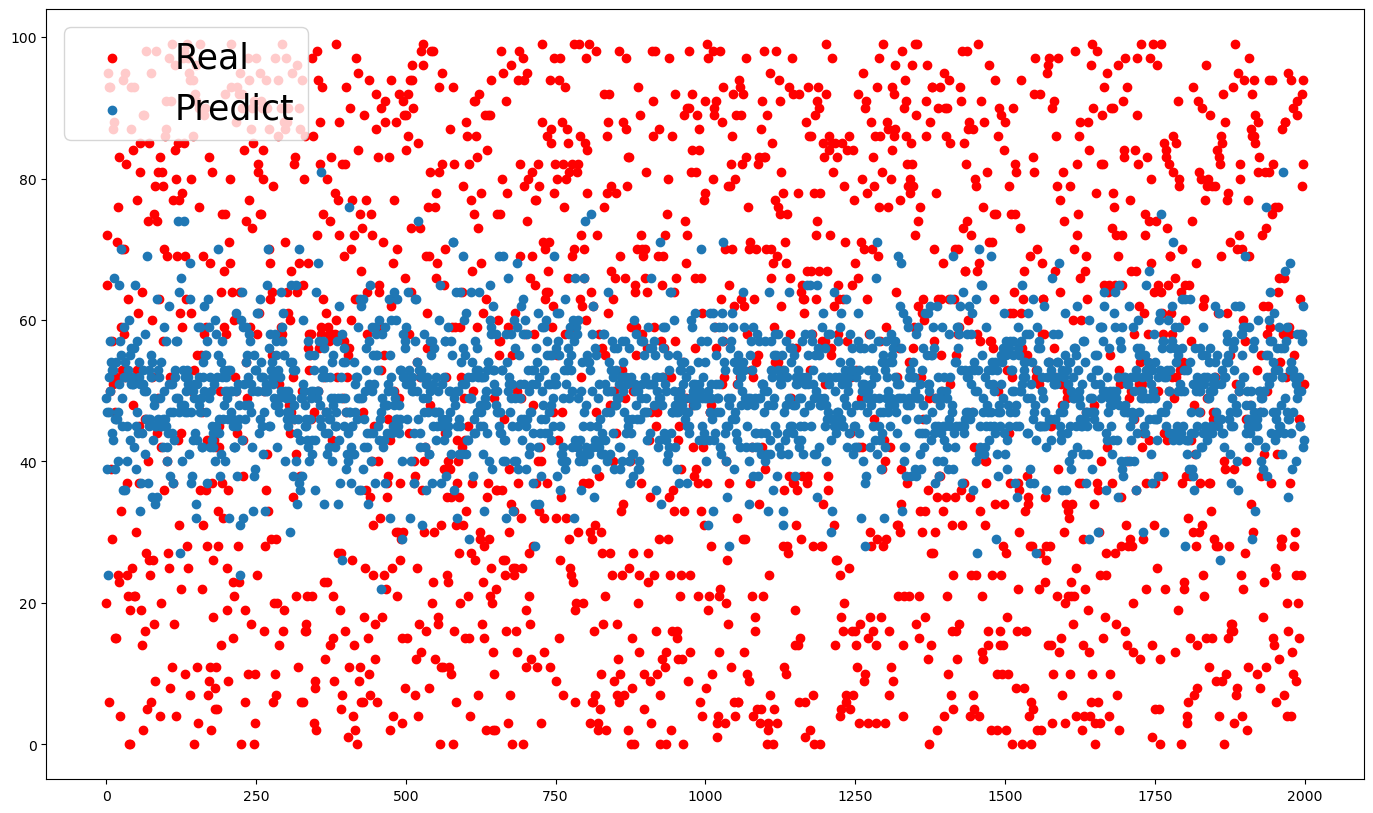

In [87]:
# Output: a scatter plot with 2000 points per colour. The real prices (red) spread from 0 to 99,
# while most predictions (blue) stay between about 40 and 60: the model does not follow the real prices.
visualize_model_results(realPrice, predPrice)

### Second attempt: predict a price band

Predicting the exact price did not work, so the next cells try an easier target. `pd.cut` puts each price into a band, 0 (up to 20), 1 (over 20 up to 50) or 2 (over 50), and inserts it as a new column `c_price`; `info()` shows the new `category` column, and the next cell checks that no row has a missing value.

In [88]:
# Why: show the table again before the new column is added.
# Output: the 10000 x 14 table.
ecom

,Address,Lot,AM or PM,Browser Info,Company,Credit Card,CC Exp Date,CC Security Code,CC Provider,Email,Job,IP Address,Language,Purchase Price
0,"16629 Pace Camp Apt. 448\nAlexisborough, NE 77...",46 in,PM,Opera/9.56.(X11; Linux x86_64; sl-SI) Presto/2...,Martinez-Herman,6011929061123406,02/20,900,JCB 16 digit,pdunlap@yahoo.com,"Scientist, product/process development",149.146.147.205,el,98.14
1,"9374 Jasmine Spurs Suite 508\nSouth John, TN 8...",28 rn,PM,Opera/8.93.(Windows 98; Win 9x 4.90; en-US) Pr...,"Fletcher, Richards and Whitaker",3337758169645356,11/18,561,Mastercard,anthony41@reed.com,Drilling engineer,15.160.41.51,fr,70.73
2,Unit 0065 Box 5052\nDPO AP 27450,94 vE,PM,Mozilla/5.0 (compatible; MSIE 9.0; Windows NT ...,"Simpson, Williams and Pham",675957666125,08/19,699,JCB 16 digit,amymiller@morales-harrison.com,Customer service manager,132.207.160.22,de,0.95
3,"7780 Julia Fords\nNew Stacy, WA 45798",36 vm,PM,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_8_0 ...,"Williams, Marshall and Buchanan",6011578504430710,02/24,384,Discover,brent16@olson-robinson.info,Drilling engineer,30.250.74.19,es,78.04
4,"23012 Munoz Drive Suite 337\nNew Cynthia, TX 5...",20 IE,AM,Opera/9.58.(X11; Linux x86_64; it-IT) Presto/2...,"Brown, Watson and Andrews",6011456623207998,10/25,678,Diners Club / Carte Blanche,christopherwright@gmail.com,Fine artist,24.140.33.94,es,77.82
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,"966 Castaneda Locks\nWest Juliafurt, CO 96415",92 XI,PM,Mozilla/5.0 (Windows NT 5.1) AppleWebKit/5352 ...,Randall-Sloan,342945015358701,03/22,838,JCB 15 digit,iscott@wade-garner.com,Printmaker,29.73.197.114,it,82.21
9996,"832 Curtis Dam Suite 785\nNorth Edwardburgh, T...",41 JY,AM,Mozilla/5.0 (compatible; MSIE 9.0; Windows NT ...,"Hale, Collins and Wilson",210033169205009,07/25,207,JCB 16 digit,mary85@hotmail.com,Energy engineer,121.133.168.51,pt,25.63
9997,Unit 4434 Box 6343\nDPO AE 28026-0283,74 Zh,AM,Mozilla/5.0 (Macintosh; U; Intel Mac OS X 10_7...,Anderson Ltd,6011539787356311,05/21,1,VISA 16 digit,tyler16@gmail.com,Veterinary surgeon,156.210.0.254,el,83.98
9998,"0096 English Rest\nRoystad, IA 12457",74 cL,PM,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_8_8;...,Cook Inc,180003348082930,11/17,987,American Express,elizabethmoore@reid.net,Local government officer,55.78.26.143,es,38.84


In [122]:
# Output: the same table as the previous cell (a leftover duplicate; you can skip it).
ecom

,Address,Lot,AM or PM,Browser Info,Company,Credit Card,CC Exp Date,CC Security Code,CC Provider,Email,Job,IP Address,Language,Purchase Price
0,"16629 Pace Camp Apt. 448\nAlexisborough, NE 77...",46 in,PM,Opera/9.56.(X11; Linux x86_64; sl-SI) Presto/2...,Martinez-Herman,6011929061123406,02/20,900,JCB 16 digit,pdunlap@yahoo.com,"Scientist, product/process development",149.146.147.205,el,98.14
1,"9374 Jasmine Spurs Suite 508\nSouth John, TN 8...",28 rn,PM,Opera/8.93.(Windows 98; Win 9x 4.90; en-US) Pr...,"Fletcher, Richards and Whitaker",3337758169645356,11/18,561,Mastercard,anthony41@reed.com,Drilling engineer,15.160.41.51,fr,70.73
2,Unit 0065 Box 5052\nDPO AP 27450,94 vE,PM,Mozilla/5.0 (compatible; MSIE 9.0; Windows NT ...,"Simpson, Williams and Pham",675957666125,08/19,699,JCB 16 digit,amymiller@morales-harrison.com,Customer service manager,132.207.160.22,de,0.95
3,"7780 Julia Fords\nNew Stacy, WA 45798",36 vm,PM,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_8_0 ...,"Williams, Marshall and Buchanan",6011578504430710,02/24,384,Discover,brent16@olson-robinson.info,Drilling engineer,30.250.74.19,es,78.04
4,"23012 Munoz Drive Suite 337\nNew Cynthia, TX 5...",20 IE,AM,Opera/9.58.(X11; Linux x86_64; it-IT) Presto/2...,"Brown, Watson and Andrews",6011456623207998,10/25,678,Diners Club / Carte Blanche,christopherwright@gmail.com,Fine artist,24.140.33.94,es,77.82
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,"966 Castaneda Locks\nWest Juliafurt, CO 96415",92 XI,PM,Mozilla/5.0 (Windows NT 5.1) AppleWebKit/5352 ...,Randall-Sloan,342945015358701,03/22,838,JCB 15 digit,iscott@wade-garner.com,Printmaker,29.73.197.114,it,82.21
9996,"832 Curtis Dam Suite 785\nNorth Edwardburgh, T...",41 JY,AM,Mozilla/5.0 (compatible; MSIE 9.0; Windows NT ...,"Hale, Collins and Wilson",210033169205009,07/25,207,JCB 16 digit,mary85@hotmail.com,Energy engineer,121.133.168.51,pt,25.63
9997,Unit 4434 Box 6343\nDPO AE 28026-0283,74 Zh,AM,Mozilla/5.0 (Macintosh; U; Intel Mac OS X 10_7...,Anderson Ltd,6011539787356311,05/21,1,VISA 16 digit,tyler16@gmail.com,Veterinary surgeon,156.210.0.254,el,83.98
9998,"0096 English Rest\nRoystad, IA 12457",74 cL,PM,Mozilla/5.0 (Macintosh; Intel Mac OS X 10_8_8;...,Cook Inc,180003348082930,11/17,987,American Express,elizabethmoore@reid.net,Local government officer,55.78.26.143,es,38.84


In [123]:
# Why: an easier target: a price band instead of the exact price.
# What: bins=[-1,20,50,100] makes the bands (-1, 20], (20, 50] and (50, 100], labelled 0, 1 and 2; -1 puts a price of 0 into band 0.
# What: insert(13, ...) puts the new column 'c_price' at position 13, just before 'Purchase Price'.
# Output: none.
# Note: running this cell twice raises a ValueError (the column already exists); run again from the read_csv cell instead.
category = pd.cut(ecom['Purchase Price'],bins=[-1,20,50,100],labels=[0,1,2])
ecom.insert(13,'c_price',category)

In [124]:
# Output: the table now has 15 columns; c_price has the dtype `category`.
ecom.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   Address           10000 non-null  str     
 1   Lot               10000 non-null  str     
 2   AM or PM          10000 non-null  str     
 3   Browser Info      10000 non-null  str     
 4   Company           10000 non-null  str     
 5   Credit Card       10000 non-null  int64   
 6   CC Exp Date       10000 non-null  str     
 7   CC Security Code  10000 non-null  int64   
 8   CC Provider       10000 non-null  str     
 9   Email             10000 non-null  str     
 10  Job               10000 non-null  str     
 11  IP Address        10000 non-null  str     
 12  Language          10000 non-null  str     
 13  c_price           10000 non-null  category
 14  Purchase Price    10000 non-null  float64 
dtypes: category(1), float64(1), int64(2), str(11)
memory usage: 673.9 KB


In [125]:
# Why: check that no row has a missing value before the second model.
# What: isnull() marks each missing cell True; any(axis=1) is True for a row with at least one missing cell.
# Output: 'Empty DataFrame': no row has a missing value.
is_NaN = ecom.isnull()
row_has_NaN = is_NaN.any(axis=1)
rows_with_NaN = ecom[row_has_NaN]

print(rows_with_NaN)

Empty DataFrame
Columns: [Address, Lot, AM or PM, Browser Info, Company, Credit Card, CC Exp Date, CC Security Code, CC Provider, Email, Job, IP Address, Language, c_price, Purchase Price]
Index: []


`X` now leaves out both price columns and `y` is the price band.

<details><summary>What do you notice?</summary>

The test score is again below 0 and the RMSE is about 0.8 on a scale from 0 to 2, so the bands are not predicted either. The plot data from the first run are still in `realPrice` and `predPrice`, because the two lists are only emptied when their cell is run again.
</details>

In [126]:
# Why: new inputs and target: leave out both price columns (the model must not see the answer) and predict the band.
# Output: none.
X = ecom.drop(['Purchase Price','c_price'], axis=1)
y = ecom['c_price'].astype(int)

In [127]:
# Output: cross-validation R² about -0.07, RMSE about 0.81 on the 0-2 scale, train score about 1.0, test score about -0.10, then 21 pairs.
# Note: the '$' in the printout is only a label here; the values are band numbers 0, 1 or 2.
# int() cuts off the decimals of the predictions, so most of them print as 1. This cell also takes several minutes.
pipeline_model(X, y, ecom)

-0.07064331943437793
MSE             : 0.6620710205542075

RMSE            : 0.8136774671540361
MAE             : 0.7117667652949115

Score (train)   : 0.9999999867982977
Score (test)    : -0.09565837421276835

Real Value      ----->>>>> 2 $
Predicted Value ----->>>>> 1 $

Real Value      ----->>>>> 1 $
Predicted Value ----->>>>> 1 $

Real Value      ----->>>>> 2 $
Predicted Value ----->>>>> 1 $

Real Value      ----->>>>> 2 $
Predicted Value ----->>>>> 1 $

Real Value      ----->>>>> 2 $
Predicted Value ----->>>>> 1 $

Real Value      ----->>>>> 2 $
Predicted Value ----->>>>> 1 $

Real Value      ----->>>>> 2 $
Predicted Value ----->>>>> 1 $

Real Value      ----->>>>> 2 $
Predicted Value ----->>>>> 1 $

Real Value      ----->>>>> 2 $
Predicted Value ----->>>>> 1 $

Real Value      ----->>>>> 2 $
Predicted Value ----->>>>> 1 $

Real Value      ----->>>>> 1 $
Predicted Value ----->>>>> 1 $

Real Value      ----->>>>> 2 $
Predicted Value ----->>>>> 1 $

Real Value      ----->>>>> 1 $
Pr

`confuse_of_results` prints a classification report (precision, recall and F1 for each class). It is only used by the commented-out line in `pipeline_model`, together with the decision tree classifier: to try it, run this cell, remove the `#` from those two lines, run the `pipeline_model` cell again and repeat the call.

In the original run of this notebook these lines were switched on with the price band as the target: about 0.40 in cross-validation and 0.42 accuracy on the test rows, below the 0.51 you get by always predicting the most common band (2).

In [129]:
# Why: an optional helper for the decision-tree variant (see the markdown above).
# Output: none; it prints a classification report only when it is called.
# Note: classification_report needs class labels, so use it with the decision tree classifier, not the linear regression.
def confuse_of_results(X_test, y_test, dtree):
    predictions = dtree.predict(X_test)
    print(classification_report(y_test,predictions))